## Seminário 2
Dataset: [Student Stress Factors: A Comprehensive Analysis](https://www.kaggle.com/datasets/rxnach/student-stress-factors-a-comprehensive-analysis)

Sobre a base de dados escolhida:
- São dados sintéticos que buscam simular fatores associados ao estresse acadêmico em uma amostra de 1100 indivíduos.
- O foco é a análise estatística em vez de tratamento dos dados (algo que foi necessário na base selecionada para o Seminário 1).
- Embora o conjunto de dados original disponha de cerca de vinte variáveis, selecionou-se um subconjunto composto por "anxiety_level", "self_esteem", "sleep_quality", "academic_performance" e "study_load". Essa delimitação fundamentou-se no objetivo de analisar a interação entre fatores psicológicos (2), acadêmicos (2) e fisiológicos (1) que apresentam forte correlação entre si.

In [1]:
import pandas as pd

In [2]:
# N° de variáveis limitado a 5, conforme estipulado na diretriz do trabalho
cols = ["anxiety_level", "self_esteem", "sleep_quality", "academic_performance", "study_load"]
df = pd.read_csv("StressLevelDataset.csv", usecols=cols)
df.head()

,anxiety_level,self_esteem,sleep_quality,academic_performance,study_load
0,14,20,2,3,2
1,15,8,1,1,4
2,12,18,2,2,3
3,16,12,1,2,4
4,16,28,5,4,3


In [3]:
# Medidas descritivas das variáveis do dataset
df.describe()

,anxiety_level,self_esteem,sleep_quality,academic_performance,study_load
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,11.063636,17.777273,2.660000,2.772727,2.621818
std,6.117558,8.944599,1.548383,1.414594,1.315781
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,11.000000,1.000000,2.000000,2.000000
50%,11.000000,19.000000,2.500000,2.000000,2.000000
75%,16.000000,26.000000,4.000000,4.000000,3.000000
max,21.000000,30.000000,5.000000,5.000000,5.000000


In [4]:
matriz_correlacao = df.corr()
matriz_correlacao

,anxiety_level,self_esteem,sleep_quality,academic_performance,study_load
anxiety_level,1.000000,-0.672745,-0.710292,-0.649601,0.586064
self_esteem,-0.672745,1.000000,0.662693,0.639045,-0.575112
sleep_quality,-0.710292,0.662693,1.000000,0.671326,-0.551775
academic_performance,-0.649601,0.639045,0.671326,1.000000,-0.520417
study_load,0.586064,-0.575112,-0.551775,-0.520417,1.000000


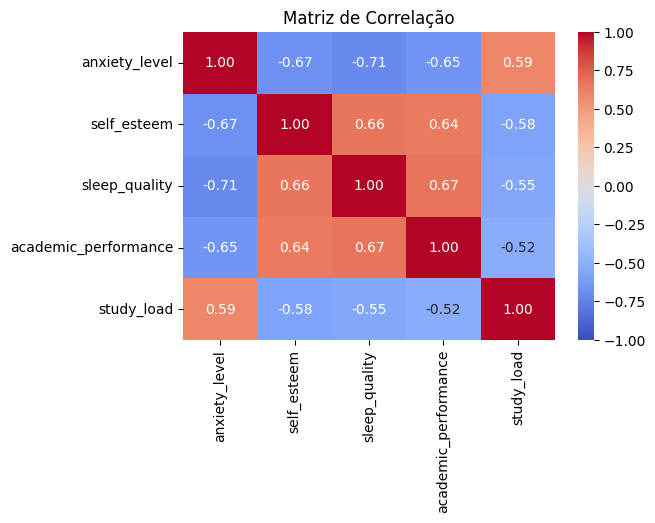

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Matriz de Correlação')
plt.show()

## PCA
A PCA implementada na biblioteca statsmodels tem a padronização dos dados como comportamento default. 

A PCA busca direções que maximizam a variância dos dados. Como a variância depende diretamente da unidade de medida (escala), qualquer variável com números maiores vai "dominar" os componentes principais de forma artificial, de modo que a padronização é necessária.  

In [6]:
import numpy as np
from statsmodels.multivariate.pca import PCA
# PCA padrão (padroniza os dados: média 0 e variância 1, equivalente à matriz de correlação)
# method='eig' é um parâmetro adicional que calcula os autovalores exatos da matriz de correlação
model = PCA(df, ncomp=5, method='eig')

In [7]:
print(model.loadings)

                        comp_0    comp_1    comp_2    comp_3    comp_4
anxiety_level        -0.464405  0.094399 -0.327777 -0.441272 -0.687938
self_esteem           0.454597 -0.057157  0.493546 -0.735082 -0.078371
sleep_quality         0.461643 -0.264211  0.119328  0.460824 -0.700343
academic_performance  0.445344 -0.376090 -0.764721 -0.225502  0.156762
study_load           -0.407706 -0.881232  0.223466 -0.041517  0.074464


In [8]:
n = df.shape[0]
autovalores = model.eigenvals.to_numpy() / n
proporcao = autovalores / autovalores.sum()
acumulada = np.cumsum(proporcao)
componentes = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']

# Tabela de Autovalores e Variância
tabela_autovalores = pd.DataFrame(
    [autovalores, proporcao, acumulada],
    index=['Autovalor', 'Proporção', 'Acumulada'],
    columns=componentes,
)

print(tabela_autovalores) # O primeiro componente explica 70% da variabilidade dos dados

                PC1       PC2       PC3       PC4       PC5
Autovalor  3.502054  0.512382  0.356451  0.344264  0.284848
Proporção  0.700411  0.102476  0.071290  0.068853  0.056970
Acumulada  0.700411  0.802887  0.874178  0.943030  1.000000


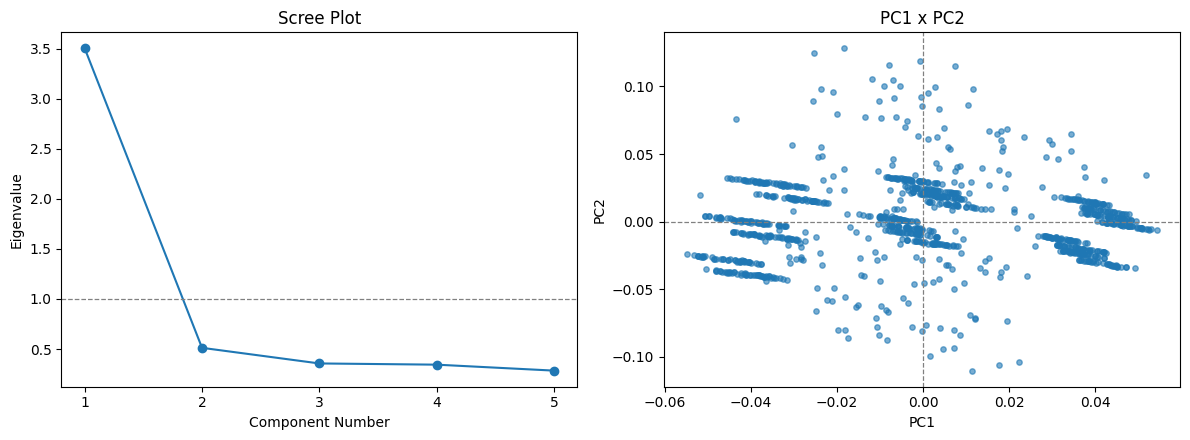

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].plot(range(1, 6), autovalores, marker='o')
axs[0].axhline(1, color='gray', ls='--', lw=0.9)   # critério de Kaiser
axs[0].set_xticks(range(1, 6)); axs[0].set_xlabel('Component Number'); axs[0].set_ylabel('Eigenvalue')
axs[0].set_title('Scree Plot')
axs[1].scatter(model.factors.iloc[:, 0], model.factors.iloc[:, 1], s=15, alpha=0.6)
axs[1].axhline(0, color='gray', ls='--', lw=0.9); axs[1].axvline(0, color='gray', ls='--', lw=0.9)
axs[1].set_xlabel('PC1'); axs[1].set_ylabel('PC2'); axs[1].set_title('PC1 x PC2')
plt.tight_layout(); plt.show()

**PC3 e PC4 (comp_2 e comp_3):** os autovalores 0,357 e 0,344 são praticamente iguais. Teste aproximado de igualdade abaixo: se não rejeitar, as duas direções não são bem determinadas individualmente e é mais seguro interpretá-las em conjunto, como variação residual.

In [10]:
from scipy.stats import chi2
lam = autovalores[2:4]; q = len(lam)
estat = n * (q * np.log(lam.mean()) - np.log(lam).sum())
gl = (q - 1) * (q + 2) / 2
print(f'H0: lambda3 = lambda4 -> estatística = {estat:.2f}, gl = {gl:.0f}, p = {chi2.sf(estat, gl):.3f}')

H0: lambda3 = lambda4 -> estatística = 0.33, gl = 2, p = 0.847


### Interpretação dos componentes
- comp_0: Índice Geral de Bem-Estar e Adaptação Acadêmica

    Explica a maior parte da variância dos dados. Apresenta pesos parecidos em magnitude, mas com sinais opostos: no polo positivo, estão variáveis de bem-estar e rendimento, enquanto que no polo negativo estão variáveis de pressão psicológica e acadêmica. Isso indica que, para a grande maioria dos estudantes, os indicadores caminharam em bloco: maior qualidade de sono, autoestima e desempenho acadêmico estão fortemente associados a menores níveis de ansiedade e menor sensação de sobrecarga nos estudos.

- comp_1: Pressão e Volume de Estudos


    É o segundo maior componente, elevando a variância acumulada para 80,29%. É fortemente dominado por study_load (-0,881), acompanhado em menor grau por academic_performance (-0,376) e sleep_quality (-0,264), todos no mesmo sentido. 
    
    Ele captura a variação ligada diretamente ao volume de estudos que não foi absorvida pelo eixo geral de bem-estar, e mostra que existe uma parcela da variabilidade em que a carga de estudo varia acompanhada de algum reflexo no desempenho acadêmico e no sono, independentemente da ansiedade (0,094) ou da autoestima (-0,057). São estudantes que enfrentam uma alta carga de estudos, mas conseguem manter bom desempenho e bom sono sem que a ansiedade (0,094) dispare. 

- comp_2: Contraste entre Desempenho Acadêmico e Autoestima

    A partir deste ponto, os autovalores estabilizam em um patamar próximo (entre 313 e 392), representando dimensões mais sutis e específicas de subgrupos da amostra.

    Esse componente retrata perfis em que o rendimento acadêmico e a autopercepção caminham em direções opostas. Por exemplo, estudantes que alcançam bom desempenho acadêmico sob certa ansiedade, mas mantêm baixa autoestima (traços de autocrítica ou perfeccionismo), ou o inverso.

- comp_3: Dissociação entre Autoestima e Qualidade do Sono

    Explica praticamente a mesma proporção de variância que o comp_2, atuando como ajuste fino da estrutura latente. Concentra-se na oposição entre self_esteem (-0,735) e sleep_quality (0,461), com anxiety_level (-0,441) acompanhando o polo de self_esteem. Isola variações residuais específicas em que a qualidade do sono não se traduz em melhora na autoestima (ou em que estudantes com boa autoestima relatam pior qualidade de sono).

- comp_4: Eixo Residual de Sono e Ansiedade

    É o componente de menor peso explicativo (5,70%), responsável por completar os 100% da variância total do sistema. Apresenta cargas altas e de mesmo sinal em sleep_quality (-0,700) e anxiety_level (-0,688), com participação quase nula das demais variáveis.

    Embora exiba cargas numericamente elevadas, seu baixo autovalor indica tratar-se de uma dimensão residual, capturando casos pontuais em que sono e ansiedade variam na mesma direção (por exemplo, aumento simultâneo de ansiedade e sono), contrariando a relação inversa dominante observada no comp_0.

### Antes de aplicar análise fatorial...
Para verificar a adequação da base de dados à Análise Fatorial, foram aplicados o índice de **Kaiser-Meyer-Olkin (KMO)** e o **teste de esfericidade de Bartlett**. 

* **Índice KMO:** O valor geral obtido foi de **0,885** (classificado como *bom* segundo os critérios de Kaiser), demonstrando que a amostra possui alta proporção de variância comum entre as variáveis.
* **Teste de Esfericidade de Bartlett:** Apresentou $\chi^2(10) = 3036,25$ com $p < 0,001$, rejeitando a hipótese nula de que a matriz de correlação seja uma matriz identidade.

Esses resultados confirmam a existência de correlações estatisticamente significativas e atestam a viabilidade técnica para a extração dos fatores latentes.

In [11]:
import numpy as np
from scipy.stats import chi2

n, p = df.shape

# Matriz de correlação (R) e sua inversa (R_inv)
R = np.corrcoef(df, rowvar=False)
R_inv = np.linalg.inv(R)

# --- 1. Teste de Bartlett ---
det_R = np.linalg.det(R)
chi2_stat = - (n - 1 - (2 * p + 5) / 6) * np.log(det_R)
gl = p * (p - 1) / 2
p_valor = chi2.sf(chi2_stat, gl)

print(f'Bartlett Qui-quadrado: {chi2_stat:.4f} (gl={int(gl)}), p-valor: {p_valor:.4e}')

# --- 2. KMO ---
# Matriz de correlações parciais anti-imagem
D = np.diag(1 / np.sqrt(np.diag(R_inv)))
Q = - D @ R_inv @ D
np.fill_diagonal(Q, 0)

R_sem_diag = R.copy()
np.fill_diagonal(R_sem_diag, 0)

kmo_geral = np.sum(R_sem_diag**2) / (np.sum(R_sem_diag**2) + np.sum(Q**2))
kmo_variaveis = np.sum(R_sem_diag**2, axis=0) / (np.sum(R_sem_diag**2, axis=0) + np.sum(Q**2, axis=0))

print(f'KMO Geral: {kmo_geral:.4f}')
for col, val in zip(cols, kmo_variaveis):
    print(f'  KMO {col}: {val:.4f}')


Bartlett Qui-quadrado: 3036.2498 (gl=10), p-valor: 0.0000e+00
KMO Geral: 0.8851
  KMO anxiety_level: 0.8689
  KMO self_esteem: 0.8884
  KMO sleep_quality: 0.8673
  KMO academic_performance: 0.8929
  KMO study_load: 0.9199


## Análise Fatorial por Componentes Principais (método da aula)

In [12]:
from statsmodels.multivariate.factor_rotation import rotate_factors

m = 2
R = df.corr().values
lam, vec = np.linalg.eigh(R)
ordem = lam.argsort()[::-1]; lam, vec = lam[ordem], vec[:, ordem]
vec = vec * np.sign(vec[1])          # sinal arbitrário: deixa self_esteem positivo

cargas = vec[:, :m] * np.sqrt(lam[:m])
comunalidade = (cargas**2).sum(axis=1)
def saida_fatorial(L, titulo):
    t = pd.DataFrame(L, index=cols, columns=[f'Factor{k+1}' for k in range(m)])
    t['Communality'] = (L**2).sum(axis=1)
    var = (L**2).sum(axis=0)
    t.loc['Variance'] = list(var) + [var.sum()]
    t.loc['% Var'] = list(var / len(cols)) + [var.sum() / len(cols)]
    print(f'=== {titulo} ==='); print(t.round(4)); print()

saida_fatorial(cargas, 'Unrotated Factor Loadings and Communalities')
coef = pd.DataFrame(cargas / lam[:m], index=cols, columns=['Factor1', 'Factor2'])
print('=== Factor Score Coefficients ==='); print(coef.round(3))
print('Unicidade / especificidade (1 - h²):'); print(pd.Series(1 - comunalidade, index=cols).round(3))

=== Unrotated Factor Loadings and Communalities ===
                      Factor1  Factor2  Communality
anxiety_level         -0.8691  -0.0676       0.7599
self_esteem            0.8507   0.0409       0.7254
sleep_quality          0.8639   0.1891       0.7821
academic_performance   0.8334   0.2692       0.7670
study_load            -0.7630   0.6308       0.9800
Variance               3.5021   0.5124       4.0144
% Var                  0.7004   0.1025       0.8029

=== Factor Score Coefficients ===
                      Factor1  Factor2
anxiety_level          -0.248   -0.132
self_esteem             0.243    0.080
sleep_quality           0.247    0.369
academic_performance    0.238    0.525
study_load             -0.218    1.231
Unicidade / especificidade (1 - h²):
anxiety_level           0.240
self_esteem             0.275
sleep_quality           0.218
academic_performance    0.233
study_load              0.020
dtype: float64


### Rotação varimax
Sem rotação, o Fator 1 é um índice geral (todas as variáveis com carga alta) e o Fator 2 é dominado por study_load. A varimax gira os eixos para que cada variável fique associada principalmente a um fator. Ela não muda as comunalidades nem a variância total explicada (80,3%), só redistribui entre os fatores. Com n = 1100, cargas acima de 0,30 já são significativas a 5% (tabela da Aula 6).

In [13]:
cargas_rot, T = rotate_factors(cargas, 'varimax')
cargas_rot = cargas_rot * np.sign(cargas_rot[[1, 4]].diagonal())   # F1 positivo em self_esteem, F2 positivo em study_load
saida_fatorial(cargas_rot, 'Rotated Factor Loadings and Communalities (Varimax)')
coef_rot = np.linalg.solve(R, cargas_rot)    # coeficientes dos escores (regressão)
print('=== Factor Score Coefficients (Varimax) ==='); print(pd.DataFrame(coef_rot, index=cols, columns=['Factor1', 'Factor2']).round(3))

=== Rotated Factor Loadings and Communalities (Varimax) ===
                      Factor1  Factor2  Communality
anxiety_level         -0.7555   0.4348       0.7599
self_esteem            0.7253  -0.4465       0.7254
sleep_quality          0.8199  -0.3316       0.7821
academic_performance   0.8399  -0.2482       0.7670
study_load            -0.2737   0.9514       0.9800
Variance               2.5494   1.4651       4.0144
% Var                  0.5099   0.2930       0.8029

=== Factor Score Coefficients (Varimax) ===
                      Factor1  Factor2
anxiety_level          -0.279    0.031
self_esteem             0.246   -0.071
sleep_quality           0.412    0.165
academic_performance    0.493    0.299
study_load              0.515    1.139


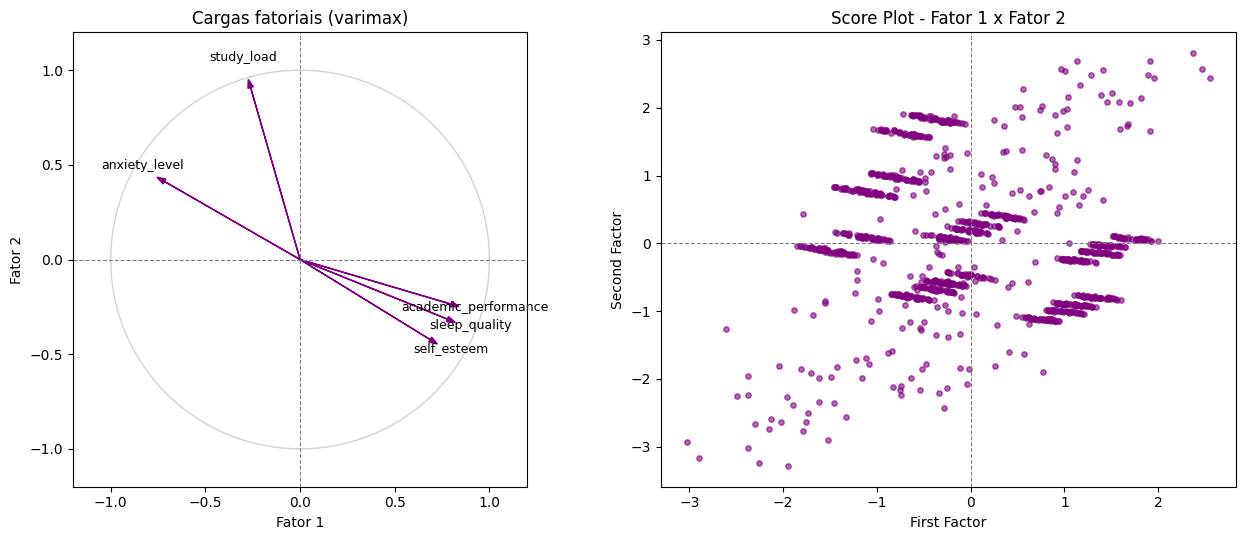

Correlação entre os escores: 0.0


In [14]:
Z = (df - df.mean()) / df.std()
escores = Z.values @ coef_rot

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
ax = axs[0]
t = np.linspace(0, 2 * np.pi, 200); ax.plot(np.cos(t), np.sin(t), color='lightgray', lw=1)
for (f1, f2), nome in zip(cargas_rot, cols):
    ax.arrow(0, 0, f1, f2, head_width=0.03, length_includes_head=True, color='purple')
    ax.text(f1 * 1.1, f2 * 1.1, nome, ha='center', fontsize=9)
ax.axhline(0, color='gray', lw=0.8, ls='--'); ax.axvline(0, color='gray', lw=0.8, ls='--')
ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect('equal')
ax.set_xlabel('Fator 1'); ax.set_ylabel('Fator 2'); ax.set_title('Cargas fatoriais (varimax)')
ax = axs[1]
ax.scatter(escores[:, 0], escores[:, 1], s=15, alpha=0.6, color='purple')
ax.axhline(0, color='gray', lw=0.8, ls='--'); ax.axvline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('First Factor'); ax.set_ylabel('Second Factor'); ax.set_title('Score Plot - Fator 1 x Fator 2')
plt.tight_layout(); plt.show()
print('Correlação entre os escores:', np.corrcoef(escores.T)[0, 1].round(3))